# 02 · Análisis exploratorio

Cada sección parte de una pregunta que un estudio pequeño se hace en torno a su lanzamiento. Las respuestas deciden cómo es el modelo (`03_modelo`) y qué enseña la aplicación.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from radar import config

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
VERDE, AZUL, ROJO = "#1e7a52", "#2f5bd7", "#b3402a"

ds = pd.read_csv(
    config.DIR_PROCESADO / "dataset_radar.csv", parse_dates=["fecha_lanzamiento"]
)
diarias = pd.read_csv(config.DIR_PROCESADO / "resenas_diarias.csv")
print(
    f"{len(ds)} lanzamientos entre {ds.fecha_lanzamiento.min():%Y-%m-%d} y {ds.fecha_lanzamiento.max():%Y-%m-%d}"
)

3019 lanzamientos entre 2025-10-29 y 2026-09-09


## P1. ¿Qué parte de las reseñas del primer mes llega en los primeros días?

dia
día 3     0.360
día 7     0.619
día 14    0.826
dtype: float64

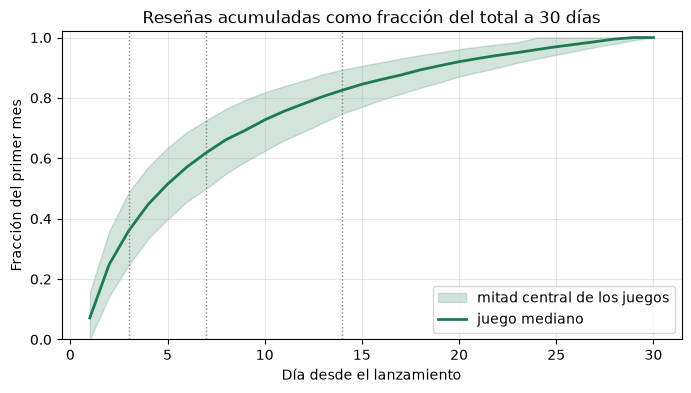

In [2]:
ventana = diarias[diarias["appid"].isin(ds["appid"]) & diarias["dia"].between(0, 29)]
tabla = ventana.pivot_table(
    index="appid", columns="dia", values="resenas", aggfunc="sum"
)
tabla = tabla.reindex(columns=range(30), fill_value=0).fillna(0)
fraccion = tabla.cumsum(axis=1).div(tabla.sum(axis=1), axis=0)

fig, ax = plt.subplots()
dias = np.arange(1, 31)
ax.fill_between(
    dias,
    fraccion.quantile(0.25),
    fraccion.quantile(0.75),
    color=VERDE,
    alpha=0.2,
    label="mitad central de los juegos",
)
ax.plot(dias, fraccion.median(), color=VERDE, lw=2, label="juego mediano")
for d in config.DIAS_LECTURA:
    ax.axvline(d, color="grey", ls=":", lw=1)
ax.set(
    title="Reseñas acumuladas como fracción del total a 30 días",
    xlabel="Día desde el lanzamiento",
    ylabel="Fracción del primer mes",
    ylim=(0, 1.02),
)
ax.legend(loc="lower right")
fraccion.median()[[d - 1 for d in config.DIAS_LECTURA]].rename(
    lambda d: f"día {d + 1}"
).round(3)

**Conclusión.** Las reseñas del primer mes llegan muy pronto: en el juego mediano, el día 3 ya está el 36 % de las que tendrá el día 30, el día 7 el 62 % y el día 14 el 83 %. La banda de la mitad central es estrecha. Es la base del radar: con una semana de datos ya se ha visto más de la mitad del mes, así que esperar al día 30 para saber si un lanzamiento va bien es perder tiempo de reacción.

## P2. ¿Las reseñas de la primera semana anticipan las del mes?

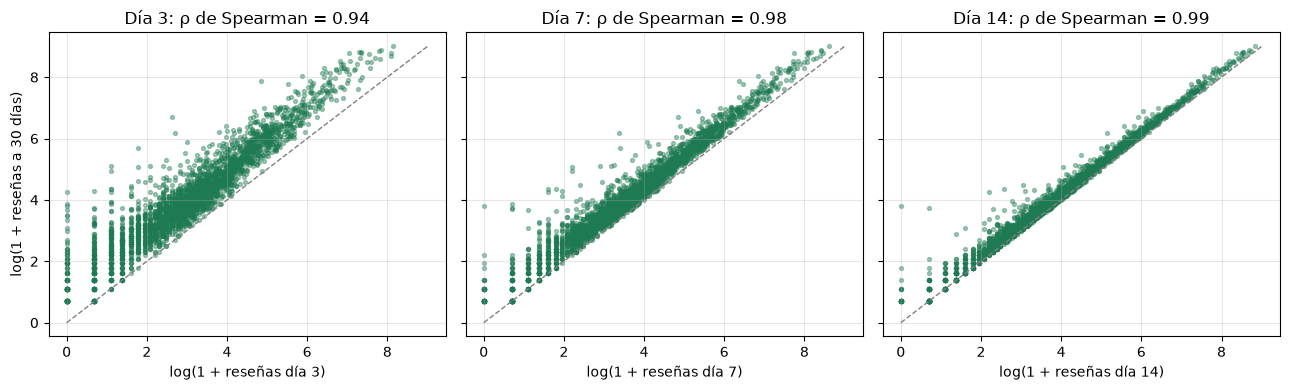

In [3]:
fig, axes = plt.subplots(1, len(config.DIAS_LECTURA), figsize=(13, 4), sharey=True)
for ax, d in zip(axes, config.DIAS_LECTURA, strict=True):
    x, y = np.log1p(ds[f"resenas_{d}d"]), np.log1p(ds["resenas_30d"])
    rho = stats.spearmanr(x, y).statistic
    ax.scatter(x, y, s=8, alpha=0.4, color=VERDE)
    ax.plot([0, y.max()], [0, y.max()], color="grey", ls="--", lw=1)
    ax.set(
        title=f"Día {d}: ρ de Spearman = {rho:.2f}", xlabel=f"log(1 + reseñas día {d})"
    )
axes[0].set_ylabel("log(1 + reseñas a 30 días)")
plt.tight_layout()

In [4]:
ratio = {
    d: (ds["resenas_30d"] / ds[f"resenas_{d}d"].replace(0, np.nan))
    for d in config.DIAS_LECTURA
}
pd.DataFrame(
    {
        f"día {d}": r.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
        for d, r in ratio.items()
    }
).round(2)

,día 3,día 7,día 14
count,2873.00,2962.00,2991.00
mean,3.57,1.88,1.30
std,4.14,1.73,0.82
min,1.00,1.00,1.00
10%,1.60,1.20,1.04
25%,2.00,1.37,1.12
50%,2.69,1.60,1.21
75%,3.81,1.99,1.33
90%,5.61,2.50,1.52
max,82.00,47.00,41.00


**Conclusión.** En escala logarítmica la relación es casi una recta (ρ de Spearman de 0,94 el día 3, 0,98 el día 7 y 0,99 el día 14). El multiplicador hasta el día 30 es estable: ×2,7 desde el día 3 (el 80 % de los juegos entre ×1,6 y ×5,6), ×1,6 desde el día 7 (entre ×1,2 y ×2,5) y ×1,2 desde el día 14. Una regla tan simple como «reseñas de hoy × multiplicador típico» ya es un baseline exigente, y el modelo tiene que ganarle para justificarse.

## P3. ¿El ritmo es igual en todos los géneros y precios?

Kruskal-Wallis entre géneros: KruskalResult(statistic=np.float64(32.97797395571878), pvalue=np.float64(2.672775412632263e-05))
Kruskal-Wallis entre bandas de precio: KruskalResult(statistic=np.float64(34.82803915948454), pvalue=np.float64(5.038902897843848e-07))


banda_precio
gratis       1.18
hasta_10     1.60
hasta_20     1.62
hasta_40     1.58
mas_de_40    1.52
Name: multiplicador_7d, dtype: float64

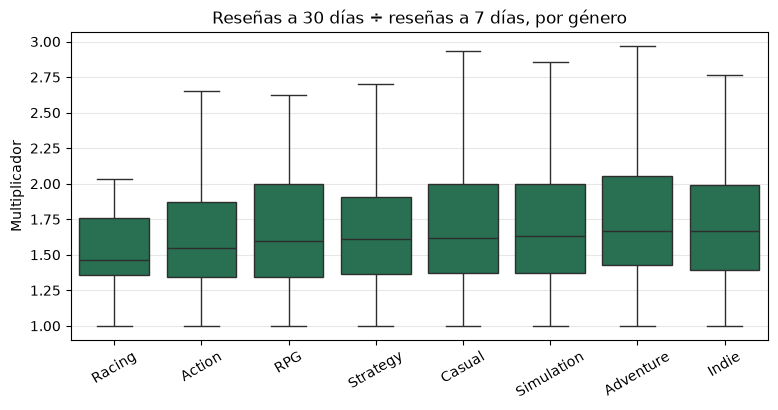

In [5]:
ds["multiplicador_7d"] = ds["resenas_30d"] / ds["resenas_7d"].replace(0, np.nan)
frecuentes = ds["genero_principal"].value_counts().loc[lambda s: s >= 15].index
sub = ds[ds["genero_principal"].isin(frecuentes)]
orden = sub.groupby("genero_principal")["multiplicador_7d"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(
    data=sub,
    x="genero_principal",
    y="multiplicador_7d",
    order=orden,
    color=VERDE,
    showfliers=False,
    ax=ax,
)
ax.set(
    title="Reseñas a 30 días ÷ reseñas a 7 días, por género",
    xlabel="",
    ylabel="Multiplicador",
)
ax.tick_params(axis="x", rotation=30)
grupos = [g["multiplicador_7d"].dropna() for _, g in sub.groupby("genero_principal")]
print("Kruskal-Wallis entre géneros:", stats.kruskal(*grupos))
grupos_b = [g["multiplicador_7d"].dropna() for _, g in ds.groupby("banda_precio")]
print("Kruskal-Wallis entre bandas de precio:", stats.kruskal(*grupos_b))
ds.groupby("banda_precio")["multiplicador_7d"].median().round(2)

**Conclusión.** El multiplicador cambia algo según el género y bastante según el precio (Kruskal-Wallis con p < 0,001 en ambos): los juegos gratuitos concentran más su mes al principio (×1,18 desde el día 7, frente a ×1,5-1,6 en los de pago). Por eso el modelo recibe precio y género además de las reseñas, y el radar compara cada juego con los de su género.

## P4. Antes de lanzar, ¿el precio o el género dicen cuántas reseñas tendrá?

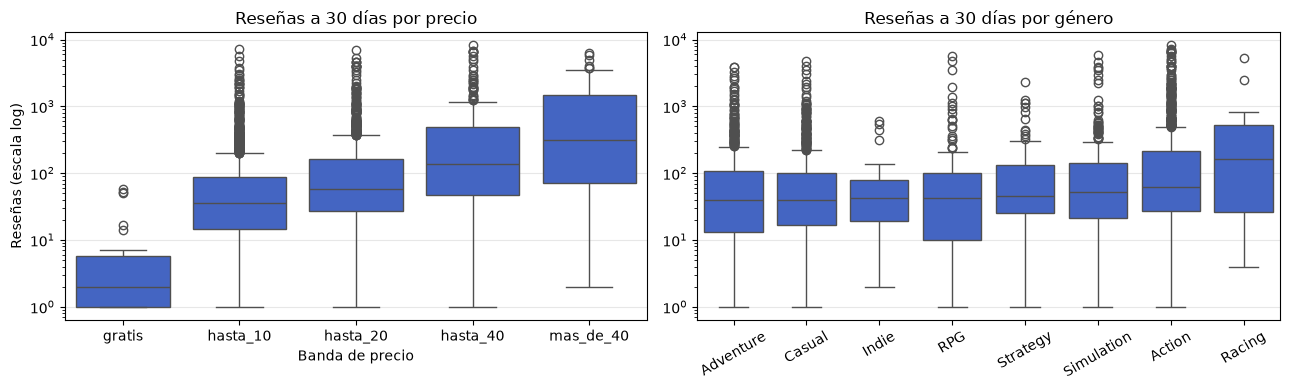

In [6]:
orden_b = ["gratis", "hasta_10", "hasta_20", "hasta_40", "mas_de_40"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(
    data=ds,
    x="banda_precio",
    y="resenas_30d",
    order=[b for b in orden_b if b in set(ds.banda_precio)],
    color=AZUL,
    ax=axes[0],
)
axes[0].set(
    yscale="log",
    title="Reseñas a 30 días por precio",
    xlabel="Banda de precio",
    ylabel="Reseñas (escala log)",
)
orden_g = sub.groupby("genero_principal")["resenas_30d"].median().sort_values().index
sns.boxplot(
    data=sub,
    x="genero_principal",
    y="resenas_30d",
    order=orden_g,
    color=AZUL,
    ax=axes[1],
)
axes[1].set(yscale="log", title="Reseñas a 30 días por género", xlabel="", ylabel="")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()

In [7]:
# Tamaño del efecto de Kruskal-Wallis; la misma función calcula la cifra que enseña la app.
from radar.eda import epsilon_cuadrado

for nombre, columna, datos in [
    ("precio", "banda_precio", ds),
    ("género", "genero_principal", sub),
]:
    grupos = [g["resenas_30d"] for _, g in datos.groupby(columna)]
    h, p = stats.kruskal(*grupos)
    print(
        f"{nombre:>7}: H = {h:.1f}, p = {p:.2g}, ε² = {epsilon_cuadrado(h, len(datos)):.3f}"
    )
print(
    "ρ precio ↔ reseñas a 30 días:",
    round(stats.spearmanr(ds.precio_usd, ds.resenas_30d).statistic, 3),
)

 precio: H = 334.9, p = 3.2e-71, ε² = 0.111
 género: H = 93.3, p = 2.6e-17, ε² = 0.031
ρ precio ↔ reseñas a 30 días: 0.359


**Conclusión.** El precio se asocia con el volumen (ρ = 0,36: los juegos más caros suelen ser producciones más grandes con más público), pero explica poco: ε² = 0,11 para el precio y 0,03 para el género. Dentro de cada banda las cajas abarcan dos órdenes de magnitud. Antes de lanzar, precio y género sirven para situar expectativas en un rango, no para dar una cifra.

## P5. ¿La opinión de las primeras reseñas añade algo al volumen?

ρ (% positivas, residuo): SignificanceResult(statistic=np.float64(0.28526820035120426), pvalue=np.float64(1.138017518197412e-44))


,count,median
pct_positivas_7d,,
"(-0.001, 0.6]",171,-0.238
"(0.6, 0.8]",470,-0.115
"(0.8, 0.9]",546,-0.049
"(0.9, 1.0]",1132,0.004


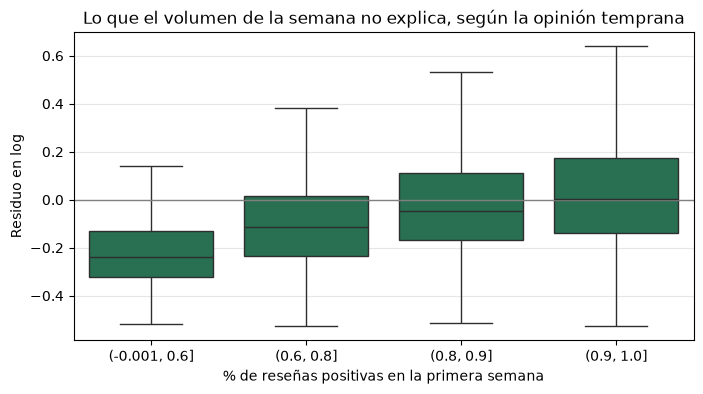

In [8]:
from radar.eda import residuos_7d

# Si el % de positivas importa, debería explicar lo que el volumen de la semana no explica.
# Residuo de la recta log(30 días) ~ log(7 días); la app enseña su mediana (radar.eda).
ds["residuo_7d"] = residuos_7d(ds)
con_pct = ds.dropna(subset=["pct_positivas_7d"])
con_pct = con_pct[con_pct["resenas_7d"] >= 10]  # con menos, el % es puro ruido
tramos = pd.cut(
    con_pct["pct_positivas_7d"], [0, 0.6, 0.8, 0.9, 1.0], include_lowest=True
)
fig, ax = plt.subplots()
sns.boxplot(x=tramos, y=con_pct["residuo_7d"], color=VERDE, showfliers=False, ax=ax)
ax.axhline(0, color="grey", lw=1)
ax.set(
    title="Lo que el volumen de la semana no explica, según la opinión temprana",
    xlabel="% de reseñas positivas en la primera semana",
    ylabel="Residuo en log",
)
print(
    "ρ (% positivas, residuo):",
    stats.spearmanr(con_pct.pct_positivas_7d, con_pct.residuo_7d),
)
con_pct.groupby(tramos, observed=True)["residuo_7d"].agg(["count", "median"]).round(3)

**Conclusión.** Sí, y en la dirección esperable: con el mismo volumen a día 7, un juego con el 60 % o menos de positivas acaba el mes un 21 % por debajo de lo que predice su volumen (residuo mediano de −0,24 en log), y uno con más del 90 % justo en lo previsto (ρ = 0,29). La opinión temprana entra como variable del modelo.

## P6. ¿Importa el mes o el día de la semana del lanzamiento?

Kruskal-Wallis por mes: KruskalResult(statistic=np.float64(60.14637807457077), pvalue=np.float64(8.709354226231614e-09))


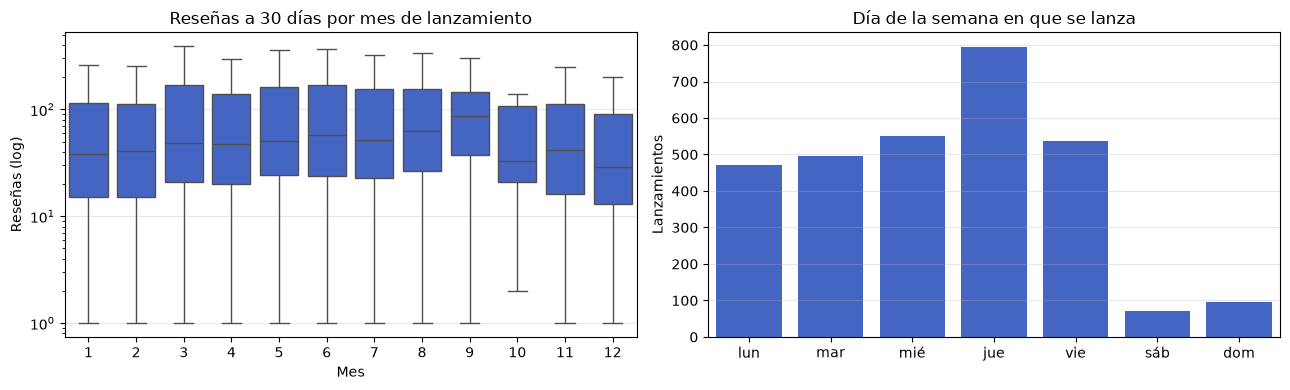

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(
    data=ds,
    x="mes_lanzamiento",
    y="resenas_30d",
    color=AZUL,
    showfliers=False,
    ax=axes[0],
)
axes[0].set(
    yscale="log",
    title="Reseñas a 30 días por mes de lanzamiento",
    xlabel="Mes",
    ylabel="Reseñas (log)",
)
dias_semana = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
sns.countplot(
    x=ds["dia_semana_lanzamiento"].map(dict(enumerate(dias_semana))),
    order=dias_semana,
    color=AZUL,
    ax=axes[1],
)
axes[1].set(title="Día de la semana en que se lanza", xlabel="", ylabel="Lanzamientos")
plt.tight_layout()
print(
    "Kruskal-Wallis por mes:",
    stats.kruskal(*[g["resenas_30d"] for _, g in ds.groupby("mes_lanzamiento")]),
)

**Conclusión.** Las diferencias por mes son estadísticamente significativas (p < 0,001), pero se confunden con el sesgo de selección que muestra P7, así que no se puede leer como «lanzar en tal mes es mejor»: septiembre, el mes más reciente, es el que más sube. Lo que sí es claro es el calendario de los estudios: el jueves concentra unos 800 lanzamientos, frente a unos 500 el resto de días laborables y menos de 100 el sábado o el domingo.

## P7. ¿Es representativa la muestra?

Mediana de reseñas a 30 días por trimestre:
fecha_lanzamiento
2025Q4    36.0
2026Q1    41.0
2026Q2    51.0
2026Q3    60.0
Freq: Q-DEC, Name: resenas_30d, dtype: float64


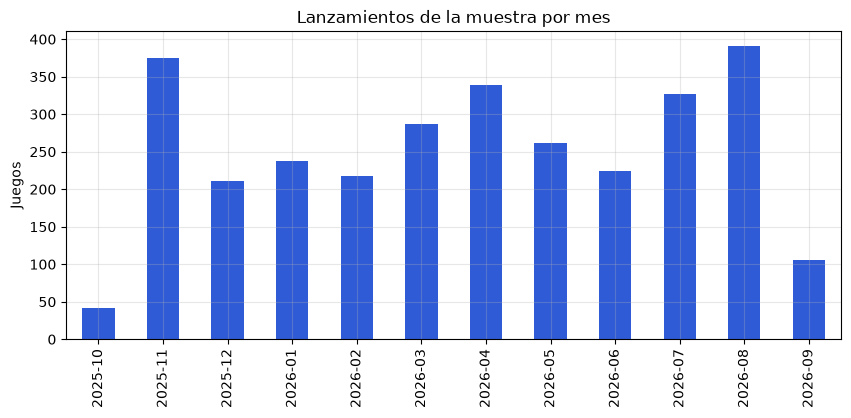

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
por_mes = ds.groupby(ds["fecha_lanzamiento"].dt.to_period("M")).size()
por_mes.plot(kind="bar", color=AZUL, ax=ax)
ax.set(title="Lanzamientos de la muestra por mes", xlabel="", ylabel="Juegos")
ax.tick_params(axis="x", rotation=90)
medianas = ds.groupby(ds["fecha_lanzamiento"].dt.to_period("Q"))["resenas_30d"].median()
print("Mediana de reseñas a 30 días por trimestre:")
print(medianas.round(0))

**Conclusión.** No del todo. La mediana de reseñas a 30 días sube trimestre a trimestre (36 → 41 → 51 → 60) porque la muestra exige 50 reseñas el día de la descarga: un juego lanzado en octubre de 2025 tuvo un año para llegar a esa cifra y uno de agosto de 2026, dos meses, así que entre los recientes solo pasan los más grandes. Afecta poco al radar, que trabaja con proporciones (reseñas de hoy frente a las del mes), pero obliga a desconfiar del mes de lanzamiento como variable previa y hace que el test, los juegos más recientes, sea algo más exigente.

## Qué implica para el modelo y la aplicación

1. **Objetivo en log(1 + reseñas)** por la asimetría (01, apartado 6).
2. **Lecturas a 3, 7 y 14 días**: con una semana ya se ve el 62 % del mes (P1).
3. **Baseline del ratio típico** (un único multiplicador para toda la muestra), porque la relación es casi lineal en log (P2); el modelo tiene que superarlo en validación para usarse.
4. **Variables extra**: porcentaje de positivas (P5), precio y género (P3).
5. **Antes de lanzar, un rango y no una cifra** (P4), y sin fiarse del mes (P6, P7).
6. **Comparación por género** en la app, porque el ritmo cambia con él (P3).